In [14]:
# Basic Import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modelling
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
import warnings

In [15]:
df = pd.read_csv('data/raw.csv')
df.head(5)

,id,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,1,male,group D,associate's degree,standard,none,52,60,58
1,2,female,group C,master's degree,standard,none,73,87,87
2,3,male,group E,associate's degree,free/reduced,none,48,44,45
3,4,male,group A,associate's degree,standard,none,58,67,66
4,5,male,group E,high school,standard,none,91,90,93


In [16]:
print("Categories in 'gender' variable:        ",end=" ")
print(df['gender'].unique())

print("Categories in 'race_ethnicity' variable: ",end=" ")
print(df['race_ethnicity'].unique())

print("Categories in 'parental level of education' variable:",end=" ")
print(df['parental_level_of_education'].unique())

print("Categories in 'lunch' variable:         ",end=" ")
print(df['lunch'].unique())

print("Categories in 'test preparation course' variable: ",end=" ")
print(df['test_preparation_course'].unique())


Categories in 'gender' variable:         <StringArray>
['male', 'female']
Length: 2, dtype: str
Categories in 'race_ethnicity' variable:  <StringArray>
['group D', 'group C', 'group E', 'group A', 'group B']
Length: 5, dtype: str
Categories in 'parental level of education' variable: <StringArray>
['associate's degree',    'master's degree',        'high school',
  'bachelor's degree',       'some college',   'some high school']
Length: 6, dtype: str
Categories in 'lunch' variable:          <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
Categories in 'test preparation course' variable:  <StringArray>
['none', 'completed']
Length: 2, dtype: str


In [17]:
y = df['math_score']
y

0       52
1       73
2       48
3       58
4       91
        ..
1995    82
1996    36
1997    43
1998    69
1999    63
Name: math_score, Length: 2000, dtype: int64

In [18]:
X = df.drop('math_score',axis=1)
X

,id,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,reading_score,writing_score
0,1,male,group D,associate's degree,standard,none,60,58
1,2,female,group C,master's degree,standard,none,87,87
2,3,male,group E,associate's degree,free/reduced,none,44,45
3,4,male,group A,associate's degree,standard,none,67,66
4,5,male,group E,high school,standard,none,90,93
...,...,...,...,...,...,...,...,...
1995,1996,male,group A,some high school,standard,none,81,83
1996,1997,female,group A,high school,free/reduced,none,46,43
1997,1998,male,group A,some high school,standard,none,43,47
1998,1999,male,group B,some college,standard,none,71,73


In [19]:
num_features = X.select_dtypes(exclude="object").columns
cat_features = X.select_dtypes(include="object").columns

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

numeric_transformer = StandardScaler()
oh_transformer = OneHotEncoder()

preprocessor = ColumnTransformer(
    [
        ("OneHotEncoder", oh_transformer, cat_features),
        ("StandardScaler", numeric_transformer, num_features),
    ]
)

In [20]:
X = preprocessor.fit_transform(X)

In [21]:
X

array([[ 0.        ,  1.        ,  0.        , ..., -1.731185  ,
        -0.66850743, -0.75990604],
       [ 1.        ,  0.        ,  0.        , ..., -1.72945295,
         1.22886465,  1.23975597],
       [ 0.        ,  1.        ,  0.        , ..., -1.7277209 ,
        -1.79287606, -1.65630625],
       ...,
       [ 0.        ,  1.        ,  1.        , ...,  1.7277209 ,
        -1.8631491 , -1.51839853],
       [ 0.        ,  1.        ,  0.        , ...,  1.72945295,
         0.10449601,  0.2744019 ],
       [ 0.        ,  1.        ,  0.        , ...,  1.731185  ,
        -0.03605007,  0.20544803]], shape=(2000, 20))

In [22]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.2 , random_state=42)

In [23]:
def evaluate_model(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mean_squared_error(true, predicted))
    r2_square = r2_score(true, predicted)
    return mae, rmse, r2_square

In [24]:
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "K-Neighbors Regressor": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest Regressor": RandomForestRegressor(),
    "XGBRegressor": XGBRegressor(),
    "CatBoosting Regressor": CatBoostRegressor(verbose=False),
    "AdaBoost Regressor": AdaBoostRegressor()
}
model_list = []
r2_list = []

for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train) # Train model
    
    # Make predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    # Evaluate Train and Test dataset
    model_train_mae , model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)
    
    model_test_mae , model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)
    
    print(list(models.keys())[i])
    model_list.append(list(models.keys())[i])
    
    print('Model performance for Training set')
    print("- Root Mean Squared Error: {:.4f}".format(model_train_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_train_mae))
    print("- R2 Score: {:.4f}".format(model_train_r2))
    
    print('Model performance for Test set')
    print("- Root Mean Squared Error: {:.4f}".format(model_test_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_test_mae))
    print("- R2 Score: {:.4f}".format(model_test_r2))
    r2_list.append(model_test_r2)
    
    print('='*35)
    print('\n')


Linear Regression
Model performance for Training set
- Root Mean Squared Error: 3.9330
- Mean Absolute Error: 3.1608
- R2 Score: 0.9227
Model performance for Test set
- Root Mean Squared Error: 4.0501
- Mean Absolute Error: 3.2163
- R2 Score: 0.9182


Lasso
Model performance for Training set
- Root Mean Squared Error: 4.5397
- Mean Absolute Error: 3.6332
- R2 Score: 0.8970
Model performance for Test set
- Root Mean Squared Error: 4.6256
- Mean Absolute Error: 3.7115
- R2 Score: 0.8934


Ridge
Model performance for Training set
- Root Mean Squared Error: 3.9330
- Mean Absolute Error: 3.1606
- R2 Score: 0.9227
Model performance for Test set
- Root Mean Squared Error: 4.0500
- Mean Absolute Error: 3.2163
- R2 Score: 0.9182


K-Neighbors Regressor
Model performance for Training set
- Root Mean Squared Error: 4.4076
- Mean Absolute Error: 3.5327
- R2 Score: 0.9029
Model performance for Test set
- Root Mean Squared Error: 5.4271
- Mean Absolute Error: 4.2245
- R2 Score: 0.8532


Decision Tre

In [25]:
pd.DataFrame(list(zip(model_list, r2_list)), columns=['Model Name', 'R2_Score']).sort_values(by=["R2_Score"], ascending=False).reset_index(drop=True)

,Model Name,R2_Score
0,Ridge,0.918248
1,Linear Regression,0.918242
2,CatBoosting Regressor,0.910903
3,Random Forest Regressor,0.908233
4,AdaBoost Regressor,0.899412
5,Lasso,0.893360
6,XGBRegressor,0.889340
7,K-Neighbors Regressor,0.853198
8,Decision Tree,0.830427


In [26]:
lin_model = LinearRegression(fit_intercept=True)
lin_model = lin_model.fit(X_train, y_train)
y_pred = lin_model.predict(X_test)
score = r2_score(y_test, y_pred)*100
print("Accuracy of the model is %.2f" %score)

Accuracy of the model is 91.82


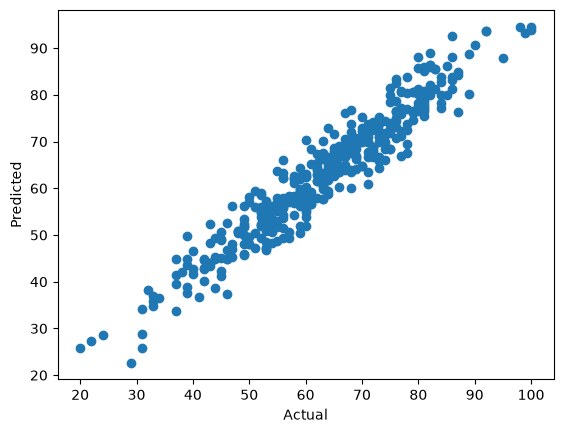

In [27]:
plt.scatter(y_test,y_pred);
plt.xlabel('Actual');
plt.ylabel('Predicted');

In [28]:
# Drop your target column (e.g., 'math_score' or whatever you are predicting)
# Ensure you DO NOT use .values or .to_numpy() here!
X = df.drop("math_score", axis=1)

y = df["math_score"]

In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [30]:
# This will now work without errors because X_train and X_test are DataFrames with column names
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [31]:
from sklearn.model_selection import train_test_split

# Ensure shuffle=True (it is True by default, but good to make explicit) and use a random_state
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=True
)

In [32]:
# If your file uses commas (standard CSV)
df = pd.read_csv('data/raw.csv')

# OR if your file uses tabs
df = pd.read_csv('data/raw.csv', sep='\t')

# OR if your file uses semicolons
df = pd.read_csv('data/raw.csv', sep=';')

In [33]:
# Basic Import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Preprocessing & Splitting
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, RandomizedSearchCV

# Modelling & Metrics
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

In [34]:
df = pd.read_csv('data/raw.csv')
df = df.drop_duplicates().reset_index(drop=True)
df.head(5)

,id,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,1,male,group D,associate's degree,standard,none,52,60,58
1,2,female,group C,master's degree,standard,none,73,87,87
2,3,male,group E,associate's degree,free/reduced,none,48,44,45
3,4,male,group A,associate's degree,standard,none,58,67,66
4,5,male,group E,high school,standard,none,91,90,93


In [35]:
print("Categories in 'gender' variable:                     ", df['gender'].unique())
print("Categories in 'race_ethnicity' variable:             ", df['race_ethnicity'].unique())
print("Categories in 'parental_level_of_education' variable:", df['parental_level_of_education'].unique())
print("Categories in 'lunch' variable:                      ", df['lunch'].unique())
print("Categories in 'test_preparation_course' variable:    ", df['test_preparation_course'].unique())

Categories in 'gender' variable:                      <StringArray>
['male', 'female']
Length: 2, dtype: str
Categories in 'race_ethnicity' variable:              <StringArray>
['group D', 'group C', 'group E', 'group A', 'group B']
Length: 5, dtype: str
Categories in 'parental_level_of_education' variable: <StringArray>
['associate's degree',    'master's degree',        'high school',
  'bachelor's degree',       'some college',   'some high school']
Length: 6, dtype: str
Categories in 'lunch' variable:                       <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
Categories in 'test_preparation_course' variable:     <StringArray>
['none', 'completed']
Length: 2, dtype: str


In [36]:
y = df['math_score']
X = df.drop(columns=['id', 'math_score'])
X.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,reading_score,writing_score
0,male,group D,associate's degree,standard,none,60,58
1,female,group C,master's degree,standard,none,87,87
2,male,group E,associate's degree,free/reduced,none,44,45
3,male,group A,associate's degree,standard,none,67,66
4,male,group E,high school,standard,none,90,93


In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=True
)

In [38]:
num_features = X_train.select_dtypes(exclude=['object', 'str']).columns
cat_features = X_train.select_dtypes(include=['object', 'str']).columns

numeric_transformer = StandardScaler()
oh_transformer = OneHotEncoder(handle_unknown='ignore')

preprocessor = ColumnTransformer(
    [
        ("OneHotEncoder", oh_transformer, cat_features),
        ("StandardScaler", numeric_transformer, num_features),
    ]
)

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (1600, 19)
X_test shape: (400, 19)


In [39]:
def evaluate_model(true, predicted):
    mae = mean_absolute_error(true, predicted)
    rmse = np.sqrt(mean_squared_error(true, predicted))
    r2_square = r2_score(true, predicted)
    return mae, rmse, r2_square

In [40]:
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "K-Neighbors Regressor": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest Regressor": RandomForestRegressor(),
    "XGBRegressor": XGBRegressor(),
    "CatBoosting Regressor": CatBoostRegressor(verbose=False),
    "AdaBoost Regressor": AdaBoostRegressor()
}

model_list = []
r2_list = []

for model_name, model in models.items():
    model.fit(X_train, y_train)
    
    # Make predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    # Evaluate Train and Test dataset
    model_train_mae, model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)
    model_test_mae, model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)
    
    print(model_name)
    model_list.append(model_name)
    
    print("Model performance for Training set")
    print(f"- Root Mean Squared Error: {model_train_rmse:.4f}")
    print(f"- Mean Absolute Error: {model_train_mae:.4f}")
    print(f"- R2 Score: {model_train_r2:.4f}")
    
    print("Model performance for Test set")
    print(f"- Root Mean Squared Error: {model_test_rmse:.4f}")
    print(f"- Mean Absolute Error: {model_test_mae:.4f}")
    print(f"- R2 Score: {model_test_r2:.4f}")
    r2_list.append(model_test_r2)
    
    print("=" * 35 + "\n")

Linear Regression
Model performance for Training set
- Root Mean Squared Error: 3.9331
- Mean Absolute Error: 3.1611
- R2 Score: 0.9227
Model performance for Test set
- Root Mean Squared Error: 4.0472
- Mean Absolute Error: 3.2139
- R2 Score: 0.9184

Lasso
Model performance for Training set
- Root Mean Squared Error: 4.5385
- Mean Absolute Error: 3.6320
- R2 Score: 0.8970
Model performance for Test set
- Root Mean Squared Error: 4.6252
- Mean Absolute Error: 3.7119
- R2 Score: 0.8934

Ridge
Model performance for Training set
- Root Mean Squared Error: 3.9331
- Mean Absolute Error: 3.1609
- R2 Score: 0.9227
Model performance for Test set
- Root Mean Squared Error: 4.0470
- Mean Absolute Error: 3.2140
- R2 Score: 0.9184

K-Neighbors Regressor
Model performance for Training set
- Root Mean Squared Error: 4.4614
- Mean Absolute Error: 3.5466
- R2 Score: 0.9005
Model performance for Test set
- Root Mean Squared Error: 5.4768
- Mean Absolute Error: 4.3120
- R2 Score: 0.8505

Decision Tree
Mo

In [41]:
results_df = pd.DataFrame(
    list(zip(model_list, r2_list)), 
    columns=['Model Name', 'R2_Score']
).sort_values(by=["R2_Score"], ascending=False).reset_index(drop=True)

results_df

,Model Name,R2_Score
0,Ridge,0.918367
1,Linear Regression,0.918362
2,CatBoosting Regressor,0.909290
3,AdaBoost Regressor,0.902410
4,Random Forest Regressor,0.900973
5,Lasso,0.893379
6,XGBRegressor,0.887906
7,K-Neighbors Regressor,0.850496
8,Decision Tree,0.800696


R2 Score of the model is 91.84%


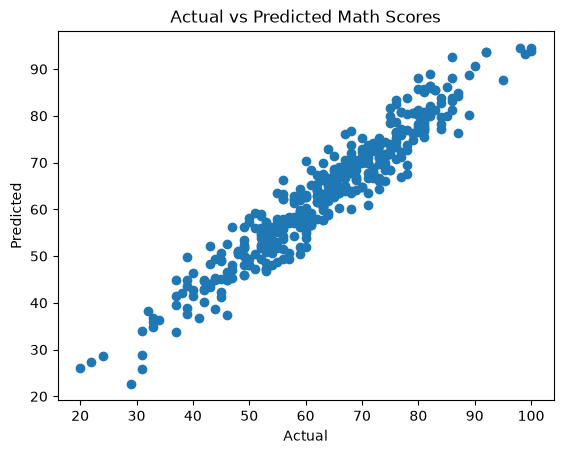

In [42]:
lin_model = LinearRegression(fit_intercept=True)
lin_model.fit(X_train, y_train)
y_pred = lin_model.predict(X_test)

score = r2_score(y_test, y_pred) * 100
print(f"R2 Score of the model is {score:.2f}%")

plt.scatter(y_test, y_pred)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted Math Scores')
plt.show()

In [43]:
# Check correlation between scores
print(df[['math_score', 'reading_score', 'writing_score']].corr())

               math_score  reading_score  writing_score
math_score       1.000000       0.905502       0.907252
reading_score    0.905502       1.000000       0.978440
writing_score    0.907252       0.978440       1.000000


In [44]:
import numpy as np
import pandas as pd

np.random.seed(42)
n = 2000

gender = np.random.choice(['male', 'female'], size=n)
race = np.random.choice(['group A', 'group B', 'group C', 'group D', 'group E'], size=n)
parent_edu = np.random.choice([
    "some high school", "high school", "some college", 
    "associate's degree", "bachelor's degree", "master's degree"
], size=n)
lunch = np.random.choice(['standard', 'free/reduced'], size=n, p=[0.65, 0.35])
test_prep = np.random.choice(['none', 'completed'], size=n, p=[0.64, 0.36])

# Create underlying student ability so scores are realistically correlated
base_ability = np.random.normal(68, 12, size=n)
base_ability += np.where(lunch == 'standard', 6, -5)
base_ability += np.where(test_prep == 'completed', 5, -3)

reading_score = np.clip(base_ability + np.random.normal(0, 4, size=n), 20, 100).astype(int)
writing_score = np.clip(0.9 * reading_score + 0.1 * base_ability + np.random.normal(0, 3, size=n), 20, 100).astype(int)
math_score = np.clip(
    0.45 * reading_score + 0.45 * writing_score + np.where(gender == 'male', 5, -4) + np.random.normal(0, 4, size=n),
    20, 100
).astype(int)

df_fixed = pd.DataFrame({
    'id': np.arange(1, n + 1),
    'gender': gender,
    'race_ethnicity': race,
    'parental_level_of_education': parent_edu,
    'lunch': lunch,
    'test_preparation_course': test_prep,
    'math_score': math_score,
    'reading_score': reading_score,
    'writing_score': writing_score
})

df_fixed.to_csv('data/raw.csv', index=False)
print("Regenerated realistic data/raw.csv successfully!")

Regenerated realistic data/raw.csv successfully!
